# Assignment 09, Problem 2 — Hussein Jawad
**E89 Deep Learning · Speech analysis: spectrogram and MFCCs of my own voice** (based on Lecture 9, the class notebook
`lec09_speech_analysis.ipynb` and the lab notebook `01_lab09_speech_mfcc_piper.ipynb`)

---

# Problem 2: Spectrogram and MFCCs of "Rice University"
Find a way to record the phrase "Rice University" in your own voice. Make it as short as possible. Calculate and display
the spectrogram of that recording. Determine the first 12 MFCC-s for every frame of length 25 msec with the stride of
10 msec. Display as a colorful 2D image the collection of those MFCC-s. Use every 3rd frame. Use any color schema of your
choice. Use `librosa` or any other suitable Python package to calculate the spectrogram and MFCC-s.

## Approach

### Goal
Record "Rice University" in my own voice, keep only the spoken phrase, and show two pictures of it: the **spectrogram**
(how strong each frequency is at each moment; Lecture 9, slide 40 shows one for the same phrase) and the first 12
**MFCCs** of every 3rd frame (a compact description of the shape of the spectrum in each frame).

### Settings

| Setting | Value |
|---|---|
| Recording | microphone in Google Colab, saved as `rice_university.wav` |
| Sample rate | 16,000 Hz (frequencies up to 8,000 Hz) |
| Frame length / stride | 25 ms = 400 samples / 10 ms = 160 samples |
| Window, FFT size | Hann, 400 (one FFT per frame, bins 40 Hz apart) |
| Mel filters, MFCCs | 40 filters, first 12 coefficients $c_0 \dots c_{11}$ |
| MFCC image | every 3rd frame (one column every 30 ms), "turbo" colors |

### Steps

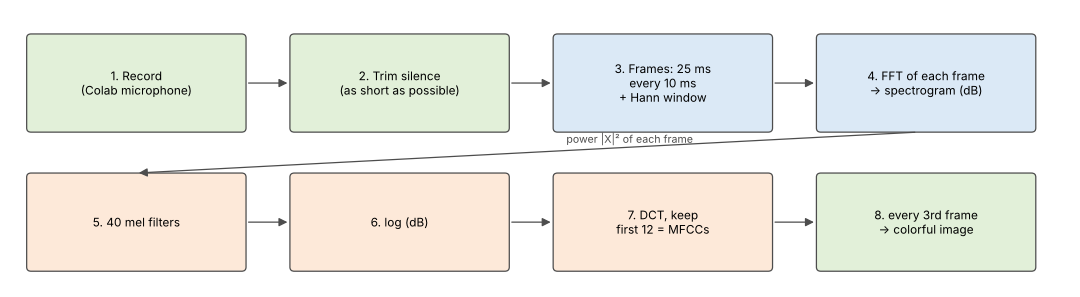

1. **Record** the phrase in Colab (Step 2) and **load** it at 16 kHz (Step 3).
2. **Trim** the silence before and after the phrase to make it as short as possible (Step 4).
3. **Spectrogram:** FFT of every 25 ms Hann-windowed frame, 10 ms apart (`librosa.stft`), shown in dB (Step 5; A.1–A.3).
4. **MFCCs** of the same frames (`librosa.feature.mfcc`): power spectrum → 40 mel filters → log → DCT, keep 12
   (Step 6; A.4–A.5).
5. **Every 3rd frame** of the MFCCs as a colorful 2D image (Step 7).

### Code
The librosa calls follow `lec09_speech_analysis.ipynb` (`librosa.load`, `librosa.feature.mfcc`,
`librosa.display.specshow`) and the frame settings follow the lab notebook (400-sample frames, 160-sample hop,
`center=False`, 40 mel filters). The recording cell (Step 2) is new.

## Solution

### Step 1: Imports

In [ ]:
import os                                    # check whether the recording file already exists
import sys                                   # detect whether the notebook runs in Google Colab
import subprocess                            # run ffmpeg, which converts the browser recording to WAV
import numpy as np                           # numerical arrays
import matplotlib.pyplot as plt              # plotting
import librosa                               # audio loading, spectrogram and MFCC calculation
import librosa.display                       # specshow: draws a spectrogram with time and frequency axes
import IPython.display as ipd                # play audio inside the notebook

### Step 2: Record "Rice University" in Google Colab
1. Run the cell below in Colab. The first time, the browser asks for the microphone: click **Allow**.
2. When **"Recording... say 'Rice University' now"** appears, say the phrase **once, quickly and clearly** (the
   recording lasts 3 seconds; the silence around the phrase is removed in Step 4).
3. The recording is saved as `rice_university.wav` and downloaded to your computer.

The cell records only if `rice_university.wav` does not exist yet; to record again, set `RECORD_NEW = True`.

In [ ]:
AUDIO_FILE = "rice_university.wav"           # the recording used by the rest of the notebook
RECORD_SECONDS = 3                           # recording length in seconds; the silence is cut off in Step 4
RECORD_NEW = False                           # True = record again even if AUDIO_FILE already exists
IN_COLAB = "google.colab" in sys.modules     # True when the notebook runs in Google Colab

RECORD_JS = '''// JavaScript that runs in the browser and records the microphone
async function recordAudio(ms) {                                            // records ms milliseconds of audio
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});  // ask the browser for the microphone
  const recorder = new MediaRecorder(stream);                               // records the microphone stream
  const chunks = [];                                                        // the pieces of recorded audio
  recorder.ondataavailable = e => chunks.push(e.data);                      // store each piece as it arrives
  const note = document.createElement("p");                                 // a line of text in the cell output
  note.style.fontSize = "18px";                                             // make the text easy to see
  note.textContent = "Recording... say 'Rice University' now";              // tell the speaker to start
  document.body.appendChild(note);                                          // show the text
  recorder.start();                                                         // start recording
  await new Promise(resolve => setTimeout(resolve, ms));                    // wait while the speaker talks
  const stopped = new Promise(resolve => recorder.onstop = resolve);        // becomes ready when the recorder stops
  recorder.stop();                                                          // stop recording
  await stopped;                                                            // wait until the last piece has arrived
  stream.getTracks().forEach(track => track.stop());                        // release the microphone
  note.textContent = "Recording finished.";                                 // tell the speaker to stop
  const blob = new Blob(chunks);                                            // join the pieces into one audio file
  return await new Promise(resolve => {                                     // turn the file into text for Python
    const reader = new FileReader();                                        // reads the file
    reader.onloadend = () => resolve(reader.result);                        // result: "data:audio/webm;base64,..."
    reader.readAsDataURL(blob);                                             // start reading
  });                                                                       // end of the conversion
}'''                                         # end of the JavaScript code

if IN_COLAB and (RECORD_NEW or not os.path.exists(AUDIO_FILE)):           # record only when needed
    from google.colab import output, files                                # Colab tools: run JavaScript, download files
    from base64 import b64decode                                          # decodes the text sent by the browser
    ipd.display(ipd.Javascript(RECORD_JS))                                # define recordAudio() in the browser
    data_url = output.eval_js(f"recordAudio({RECORD_SECONDS * 1000})")    # record, then receive the audio as text
    with open("recording.webm", "wb") as fh:                              # the browser records in WebM format
        fh.write(b64decode(data_url.split(",")[1]))                       # save the decoded audio bytes
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error",                 # ffmpeg converts the recording:
                    "-i", "recording.webm",                               # from the WebM file
                    "-ac", "1", "-ar", "16000", AUDIO_FILE],              # to mono WAV with 16,000 samples per second
                   check=True)                                            # stop with an error if the conversion fails
    files.download(AUDIO_FILE)                                            # save a copy of the WAV file on your computer

if not os.path.exists(AUDIO_FILE):                                        # outside Colab the file must already exist
    raise FileNotFoundError(f"{AUDIO_FILE} not found: run this notebook in Google Colab to record it, "  # explain how
                            f"or put a recording with this name next to the notebook")             # to fix it
print("Using the recording:", AUDIO_FILE)                                 # confirm which file is analyzed

### Step 3: Load the recording

In [ ]:
y_full, sr = librosa.load(AUDIO_FILE, sr=16000)   # read the file as mono samples in [-1, 1], resampled to 16 kHz
print(f"sample rate: {sr} Hz | duration: {len(y_full) / sr:.3f} s")  # basic facts about the recording
ipd.display(ipd.Audio(y_full, rate=sr))           # play the full recording

### Step 4: Make the recording as short as possible
`librosa.effects.trim` removes the frames at both ends that are more than `TOP_DB` = 35 dB quieter than the loudest frame.
Listen to the result: if the "R" or the "-ty" was cut off, increase `TOP_DB` (e.g. 40); if silence remains, decrease it.

In [ ]:
WIN = int(0.025 * sr)                        # frame length: 25 ms = 400 samples at 16 kHz
HOP = int(0.010 * sr)                        # stride between frames: 10 ms = 160 samples
TOP_DB = 35                                  # frames more than 35 dB below the loudest frame count as silence

y, (start, end) = librosa.effects.trim(y_full, top_db=TOP_DB, frame_length=WIN, hop_length=HOP)  # cut both ends
print(f"trimmed: {len(y) / sr:.3f} s (was {len(y_full) / sr:.3f} s)")  # length before and after trimming
ipd.display(ipd.Audio(y, rate=sr))           # listen: the whole phrase must still be there

### Step 5: The spectrogram
Each 25 ms frame (Hann window, 10 ms stride) becomes one column: 201 frequency bins from 0 to 8,000 Hz, in dB relative to
the loudest point.

In [ ]:
S = librosa.stft(y, n_fft=WIN, win_length=WIN, hop_length=HOP,   # FFT of every 25 ms frame, 10 ms apart,
                 window="hann", center=False)                    # with a Hann window and no padding at the ends
S_db = librosa.amplitude_to_db(np.abs(S), ref=np.max)            # magnitude in dB; 0 dB = loudest point
t_frames = (np.arange(S.shape[1]) * HOP + WIN / 2) / sr          # time at the middle of each frame, in seconds
print("spectrogram shape (frequency bins, frames):", S.shape)    # 201 bins, one column per frame

fig, ax = plt.subplots(figsize=(12, 5.5))                        # one wide figure
img = librosa.display.specshow(S_db, sr=sr, hop_length=HOP, x_coords=t_frames,  # draw the dB values at frame times
                               x_axis="time", y_axis="hz",                     # time across, frequency (Hz) up
                               cmap="jet", vmin=-80, vmax=0, ax=ax)             # colorful scale from -80 to 0 dB
ax.set_title('Spectrogram of "Rice University" (25 ms Hann frames, 10 ms stride)')  # plot title
ax.set_xlabel("time (s)")                                        # horizontal axis label
ax.set_ylabel("frequency (Hz)")                                  # vertical axis label
fig.colorbar(img, ax=ax, format="%+.0f dB")                      # color scale in dB
plt.show()                                                       # render the figure

### Step 6: The first 12 MFCCs of every frame
Same frames as Step 5; for each frame librosa computes the power spectrum, 40 mel filter energies, their log and a DCT,
and keeps the first 12 values.

In [ ]:
N_MFCC = 12                                  # the problem asks for the first 12 MFCCs
N_MELS = 40                                  # number of mel filters (as in the lab notebook)

mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC,          # first 12 MFCCs of every frame:
                            n_fft=WIN, win_length=WIN, hop_length=HOP,  # 25 ms frames every 10 ms (as in Step 5),
                            window="hann", center=False,         # Hann window, no padding at the ends,
                            n_mels=N_MELS)                       # 40 mel filters
print("MFCC array shape (coefficients, frames):", mfcc.shape)  # 12 rows, one column per frame

### Step 7: Every 3rd frame as a colorful 2D image
Columns are frames 0, 3, 6, … (one every 30 ms); rows are $c_0$ (bottom) to $c_{11}$ (top).

In [ ]:
mfcc3 = mfcc[:, ::3]                         # keep every 3rd frame: frames 0, 3, 6, ...
t3 = t_frames[::3]                           # middle times of the kept frames
print("kept frames:", mfcc3.shape[1], "of", mfcc.shape[1])  # how many columns the image has

fig, ax = plt.subplots(figsize=(12, 5))                         # one wide figure
im = ax.imshow(mfcc3, aspect="auto", origin="lower", cmap="turbo",   # colorful image, c0 at the bottom,
               extent=[t3[0] - 0.015, t3[-1] + 0.015, -0.5, N_MFCC - 0.5],  # each column 30 ms wide
               interpolation="nearest")                         # one sharp block per value
ax.set_yticks(range(N_MFCC))                                    # one tick per coefficient
ax.set_yticklabels([f"c{i}" for i in range(N_MFCC)])            # label the rows c0 ... c11
ax.set_xlabel("time (s), middle of each kept frame")           # horizontal axis label
ax.set_ylabel("MFCC")                                           # vertical axis label
ax.set_title('First 12 MFCCs of every 3rd frame of "Rice University"')  # plot title
fig.colorbar(im, ax=ax, label="MFCC value")                     # color scale
plt.show()                                                      # render the figure

## Results and discussion
* **Spectrogram** (compare Lecture 9, slide 40): the vowels are the bright parts, made of evenly spaced horizontal lines
  (the **harmonics** of the voice) with brighter bands across them (the **formants**, which move as the vowel changes).
  The two **"s"** sounds look different: noise spread over the high frequencies with no harmonics. Weak consonants
  ("n", "v", "t") are darker.
* **MFCC image:** each column summarizes the shape of the spectrum of one 25 ms frame in 12 numbers instead of 201. $c_0$
  (the average log mel energy) is much larger in size than the others and takes most of the color range. $c_1$ (low vs
  high frequencies) is high in vowels and drops in the two "s" sounds; the columns change at the boundaries between
  sounds, which is what makes MFCCs useful features for speech recognition.

---
# Appendix: From a recording to MFCCs

## A.1 Frames and the Hann window
Speech changes all the time but is nearly steady over a few tens of milliseconds, so it is cut into short overlapping
frames (Lecture 9, slide 36): 25 ms long, a new one every 10 ms. Each frame is multiplied by a Hann window, which fades it
in and out so the FFT does not see sharp edges (slide 38). "Every 3rd frame" means one frame every 30 ms.

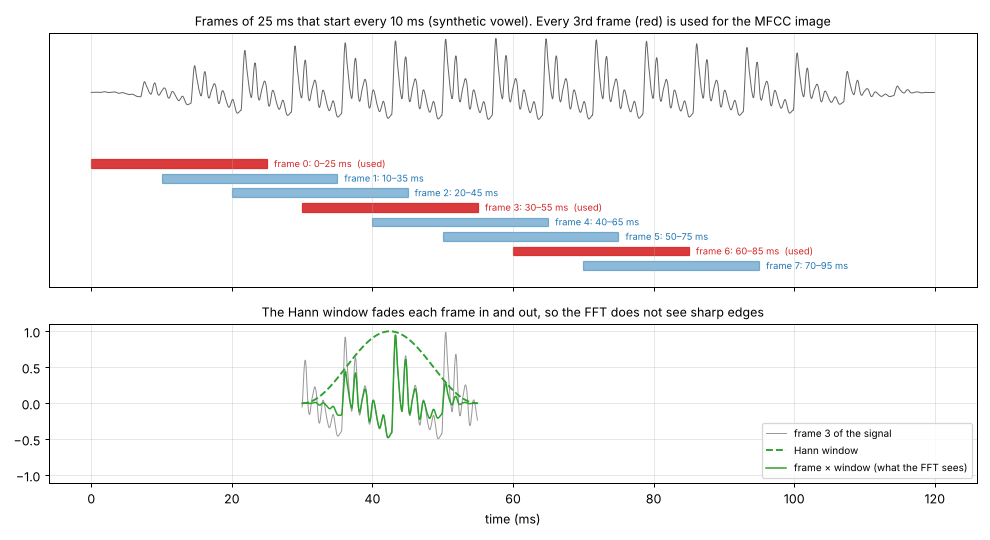

## A.2 One frame → one column: harmonics and formants
The FFT of a frame shows how strong each frequency is; the spectra of all frames side by side form the spectrogram. In a
vowel, the vocal cords produce **harmonics** (peaks every pitch frequency) and the mouth and throat shape them into
**formants** (the smooth envelope's peaks F1, F2, F3), which identify the vowel (source–filter model, Lecture 9, slide 8).

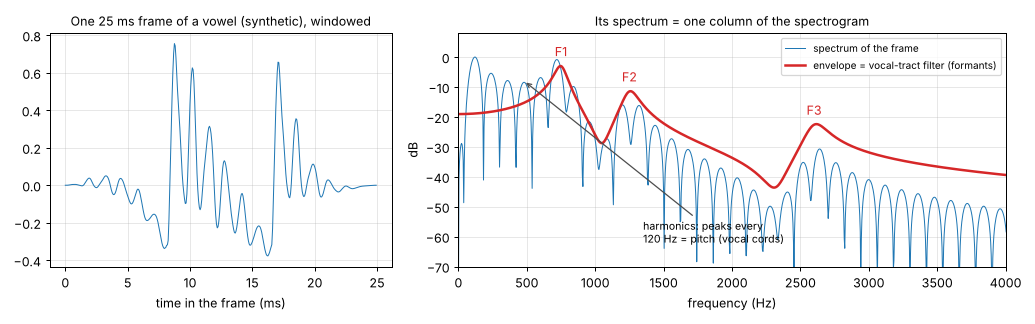

## A.3 Reading a speech spectrogram
Vowels: harmonics and formants. "s": noise at high frequencies, no harmonics. Silence: dark. Formants move when a vowel
glides, e.g. F2 rises in "Rice" (/aɪ/) and falls in "U" (/ju/). Synthetic example with the same settings:

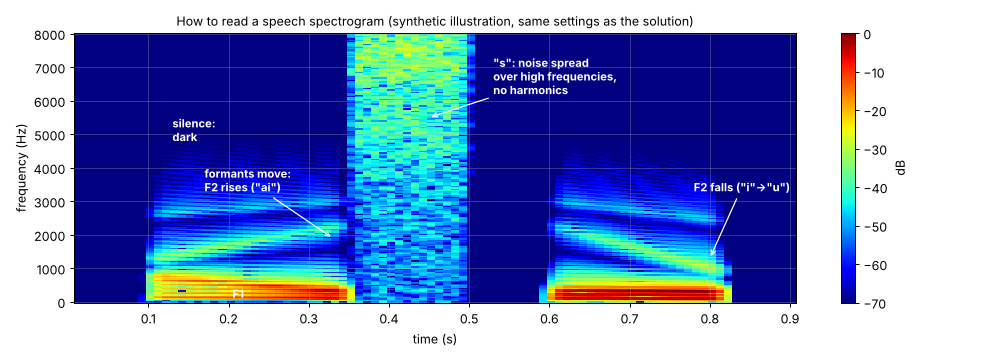

## A.4 Mel filter bank
We hear pitch differences much better at low frequencies than at high ones. The **mel scale** follows our hearing
(lecture: $\text{mel} = 2595\log_{10}(1 + f/700)$; librosa's default is the closely related Slaney version). 40
triangular filters equally spaced in mel (narrow at low, wide at high frequencies) turn the 201 FFT values of a frame
into 40 mel energies (Lecture 9, slides 64–66).

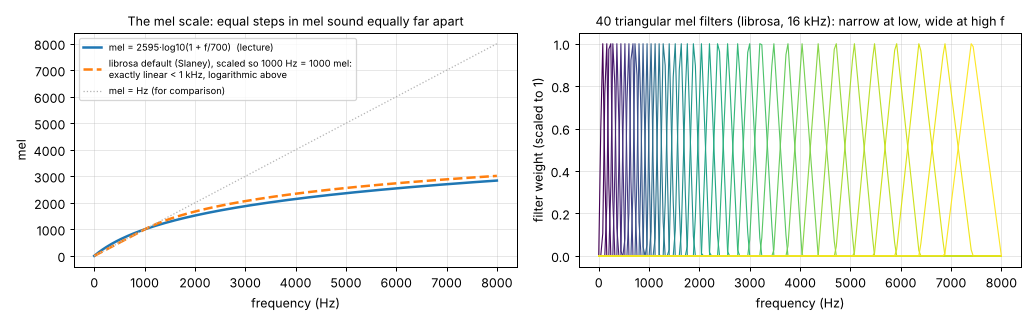

## A.5 Log and DCT → MFCCs
The 40 mel energies are converted to a log scale (dB), and a **discrete cosine transform** describes them as a sum of
cosine patterns; MFCC $c_n$ is the amount of pattern $n$ (Lecture 9, slides 67–78). $c_0$ (flat pattern) is the average
log energy, $c_1$ compares low with high frequencies, and higher coefficients describe finer detail. Keeping the first
12 keeps the smooth envelope (the formants) and drops the fine detail (the pitch harmonics).

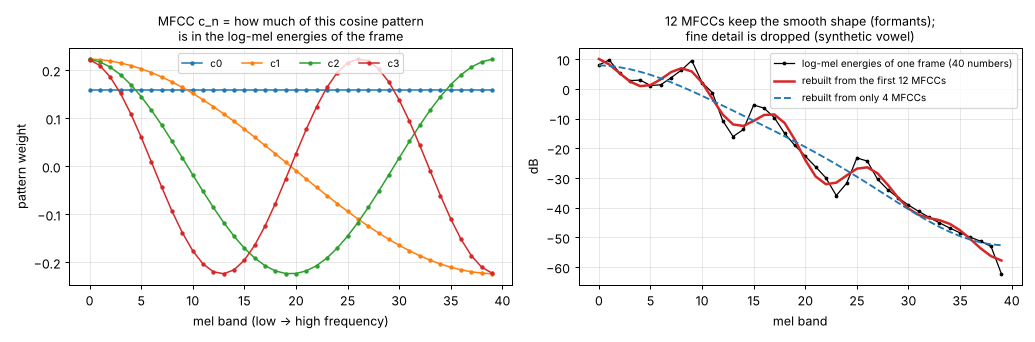